# 02 - Raisin Classification
**AIN3101 Machine Learning Project** - Badr University in Assiut, Fall 2026

Binary classification of two raisin varieties (Kecimen and Besni) with Logistic Regression, Random Forest and SVM.
This notebook follows the same stages as `01_dry_bean.ipynb`; only the parts that differ are changed.

Dataset: Raisin (UCI id=850), Cinar, Koklu & Tasdemir (2020), license CC BY 4.0.

In [1]:
import sys
sys.path.append("..")   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, RocCurveDisplay

from src.utils import *

## Stage 1: Understand the problem and the features
The task is **binary classification**: predict the raisin variety (`Class`: Kecimen or Besni) from 7 numeric
features measured on images of the grains:
Area, MajorAxisLength, MinorAxisLength, Eccentricity, ConvexArea, Extent, Perimeter.

In [2]:
df = pd.read_excel("../data/raisin/Raisin_Dataset.xlsx")
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [3]:
print(pd.read_excel("../data/raisin/Raisin_Dataset.xlsx", sheet_name="Citation_Request", header=None).iloc[0, 0])

Citation Request :
CINAR I., KOKLU M. and TASDEMIR S., (2020). Classification of Raisin Grains Using Machine Vision and Artificial Intelligence Methods, Gazi Journal of Engineering Sciences, vol. 6, no. 3, pp. 200-209, December, 2020, DOI: https://doi.org/10.30855/gmbd.2020.03.03


## Stage 2: Quality check

In [4]:
quality_check(df)
print()
print(df["Class"].value_counts())

Shape: (900, 8)
Missing values: 0
Duplicate rows: 0

Data types:
float64    5
int64      2
str        1
Name: count, dtype: int64

Class
Kecimen    450
Besni      450
Name: count, dtype: int64


The Raisin data is already clean: **0 missing values and 0 duplicate rows**, 7 numeric features and one text target.
The two classes are perfectly balanced (450 each), so nothing has to be removed.

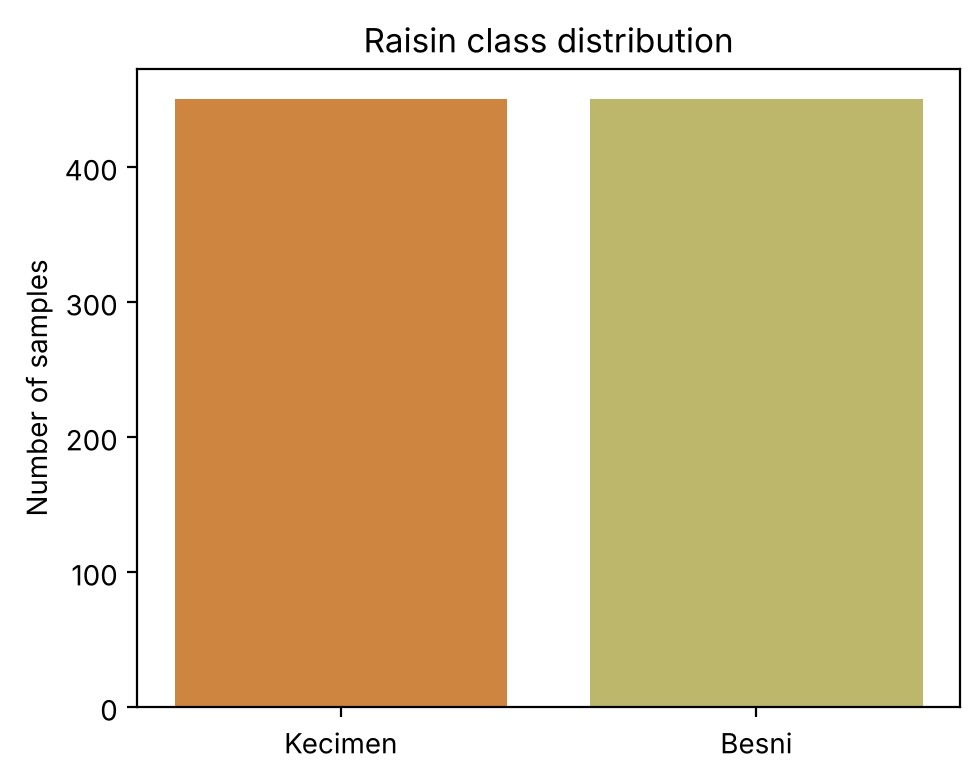

In [5]:
# fig10: class distribution
counts = df["Class"].value_counts()
plt.figure(figsize=(5, 4))
plt.bar(counts.index, counts.values, color=["peru", "darkkhaki"])
plt.ylabel("Number of samples")
plt.title("Raisin class distribution")
plt.tight_layout()
plt.savefig(FIG_DIR + "fig10_raisin_class_distribution.png", dpi=150)
plt.show()

## Stage 3: Train/test split
Same as Dry Bean: 80/20, `stratify=y`, `random_state=42`. The test set has only 180 rows, so one test score can
move a lot by chance. That is why we use **repeated** stratified CV (5 folds x 3 repeats) during tuning.

In [6]:
X = df.drop(columns="Class")
y_names = df["Class"]

encoder = LabelEncoder()
y = encoder.fit_transform(y_names)
class_names = encoder.classes_
print(dict(zip(class_names, range(len(class_names)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)

{'Besni': 0, 'Kecimen': 1}
Train: (720, 7)  Test: (180, 7)


## Stage 4: EDA (training set only)

In [7]:
X_train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,720.0,88568.854,39302.473,25387.000,59710.250,79153.500,105953.500,235047.000
MajorAxisLength,720.0,433.481,117.459,225.630,346.267,408.698,496.825,997.292
MinorAxisLength,720.0,255.278,49.836,143.711,220.010,248.943,281.448,492.275
Eccentricity,720.0,0.783,0.090,0.349,0.742,0.798,0.844,0.962
ConvexArea,720.0,92006.253,41154.891,26139.000,62056.000,82361.000,109212.750,278217.000
Extent,720.0,0.699,0.053,0.380,0.673,0.706,0.735,0.824
Perimeter,720.0,1171.656,275.996,619.074,970.888,1128.240,1311.251,2697.753


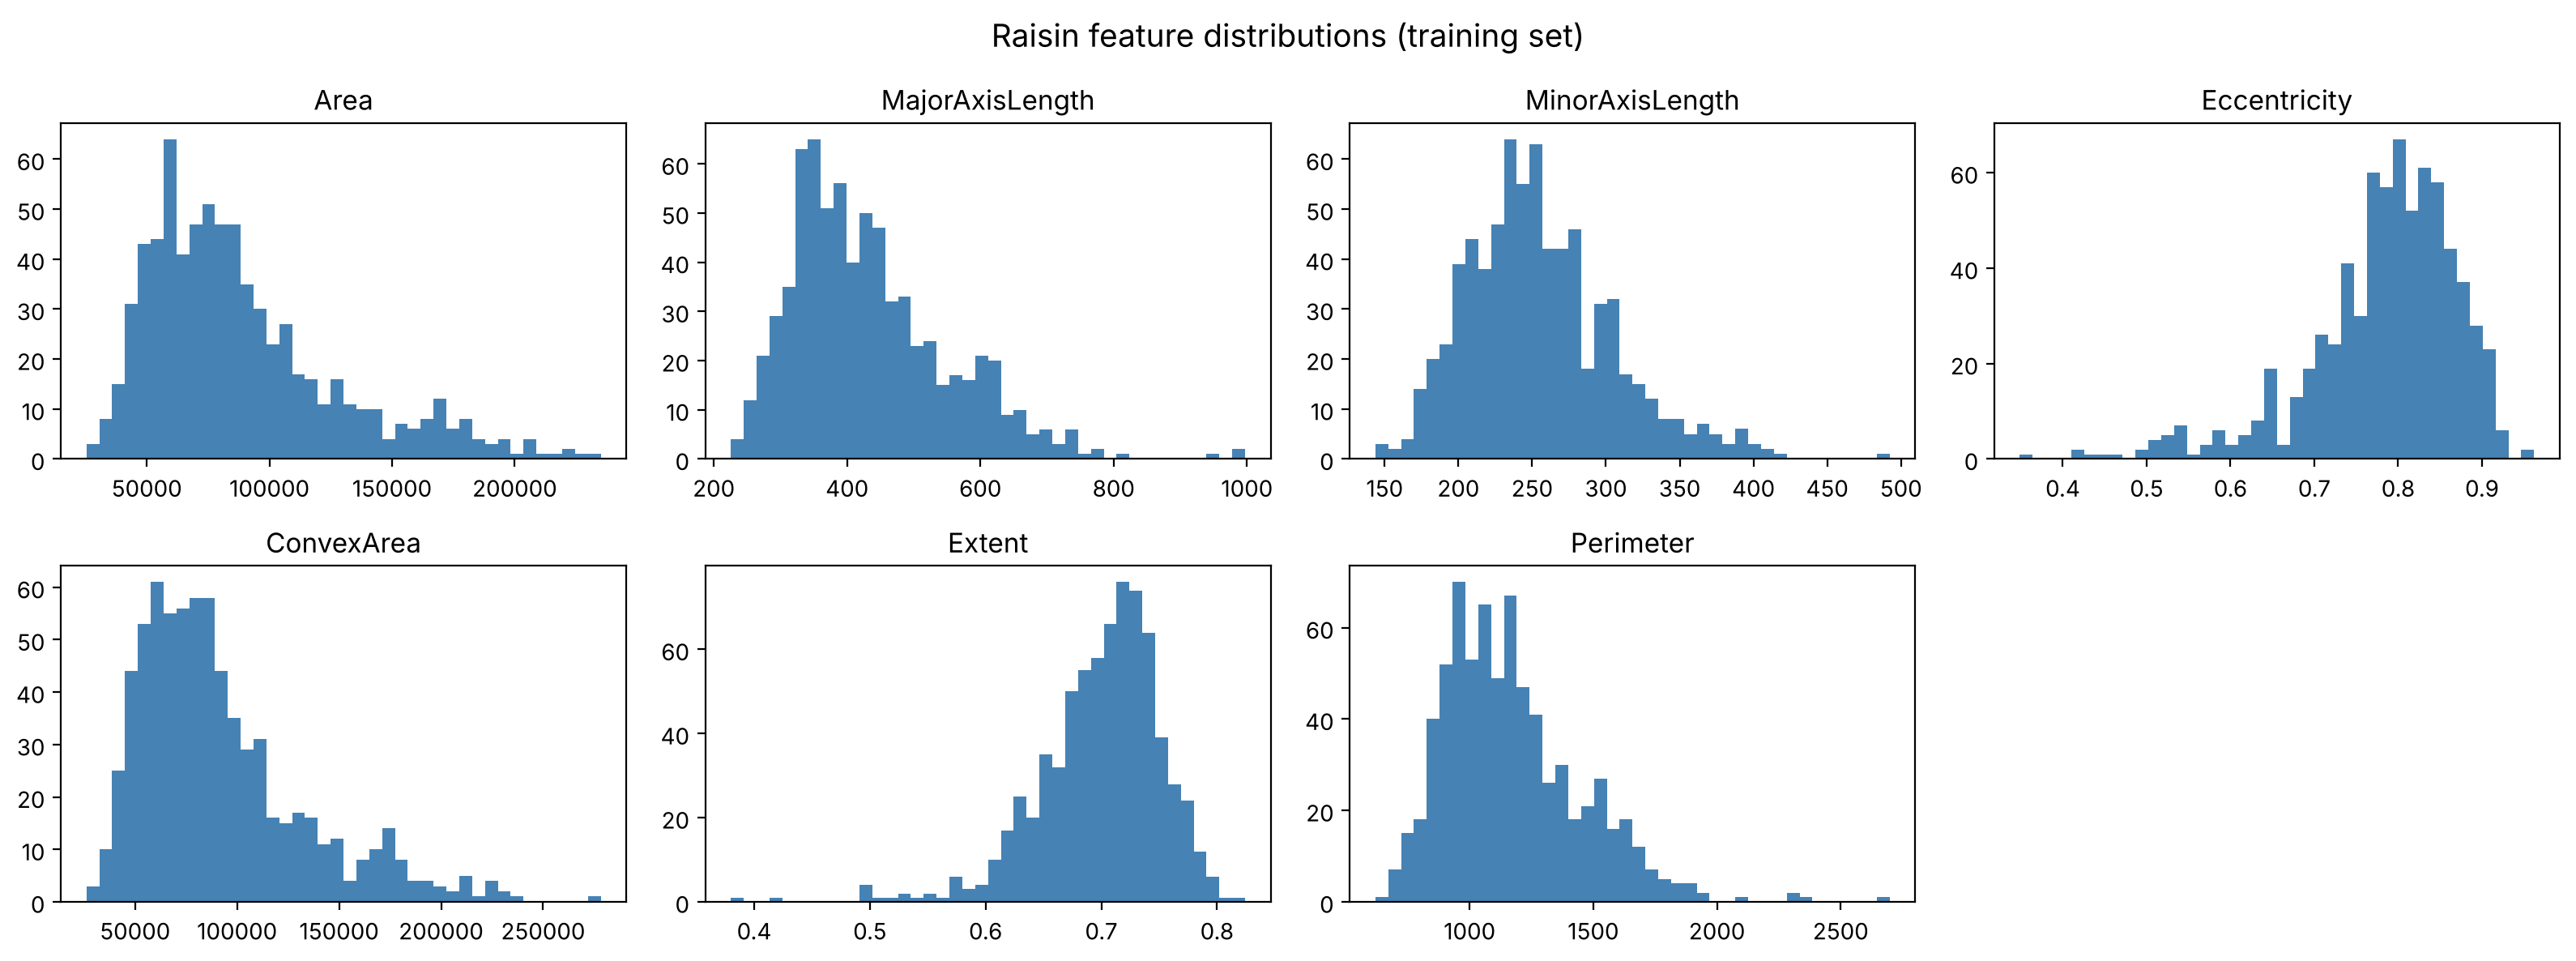

In [8]:
plot_histograms(X_train, "Raisin feature distributions (training set)",
                "fig11_raisin_histograms.png")

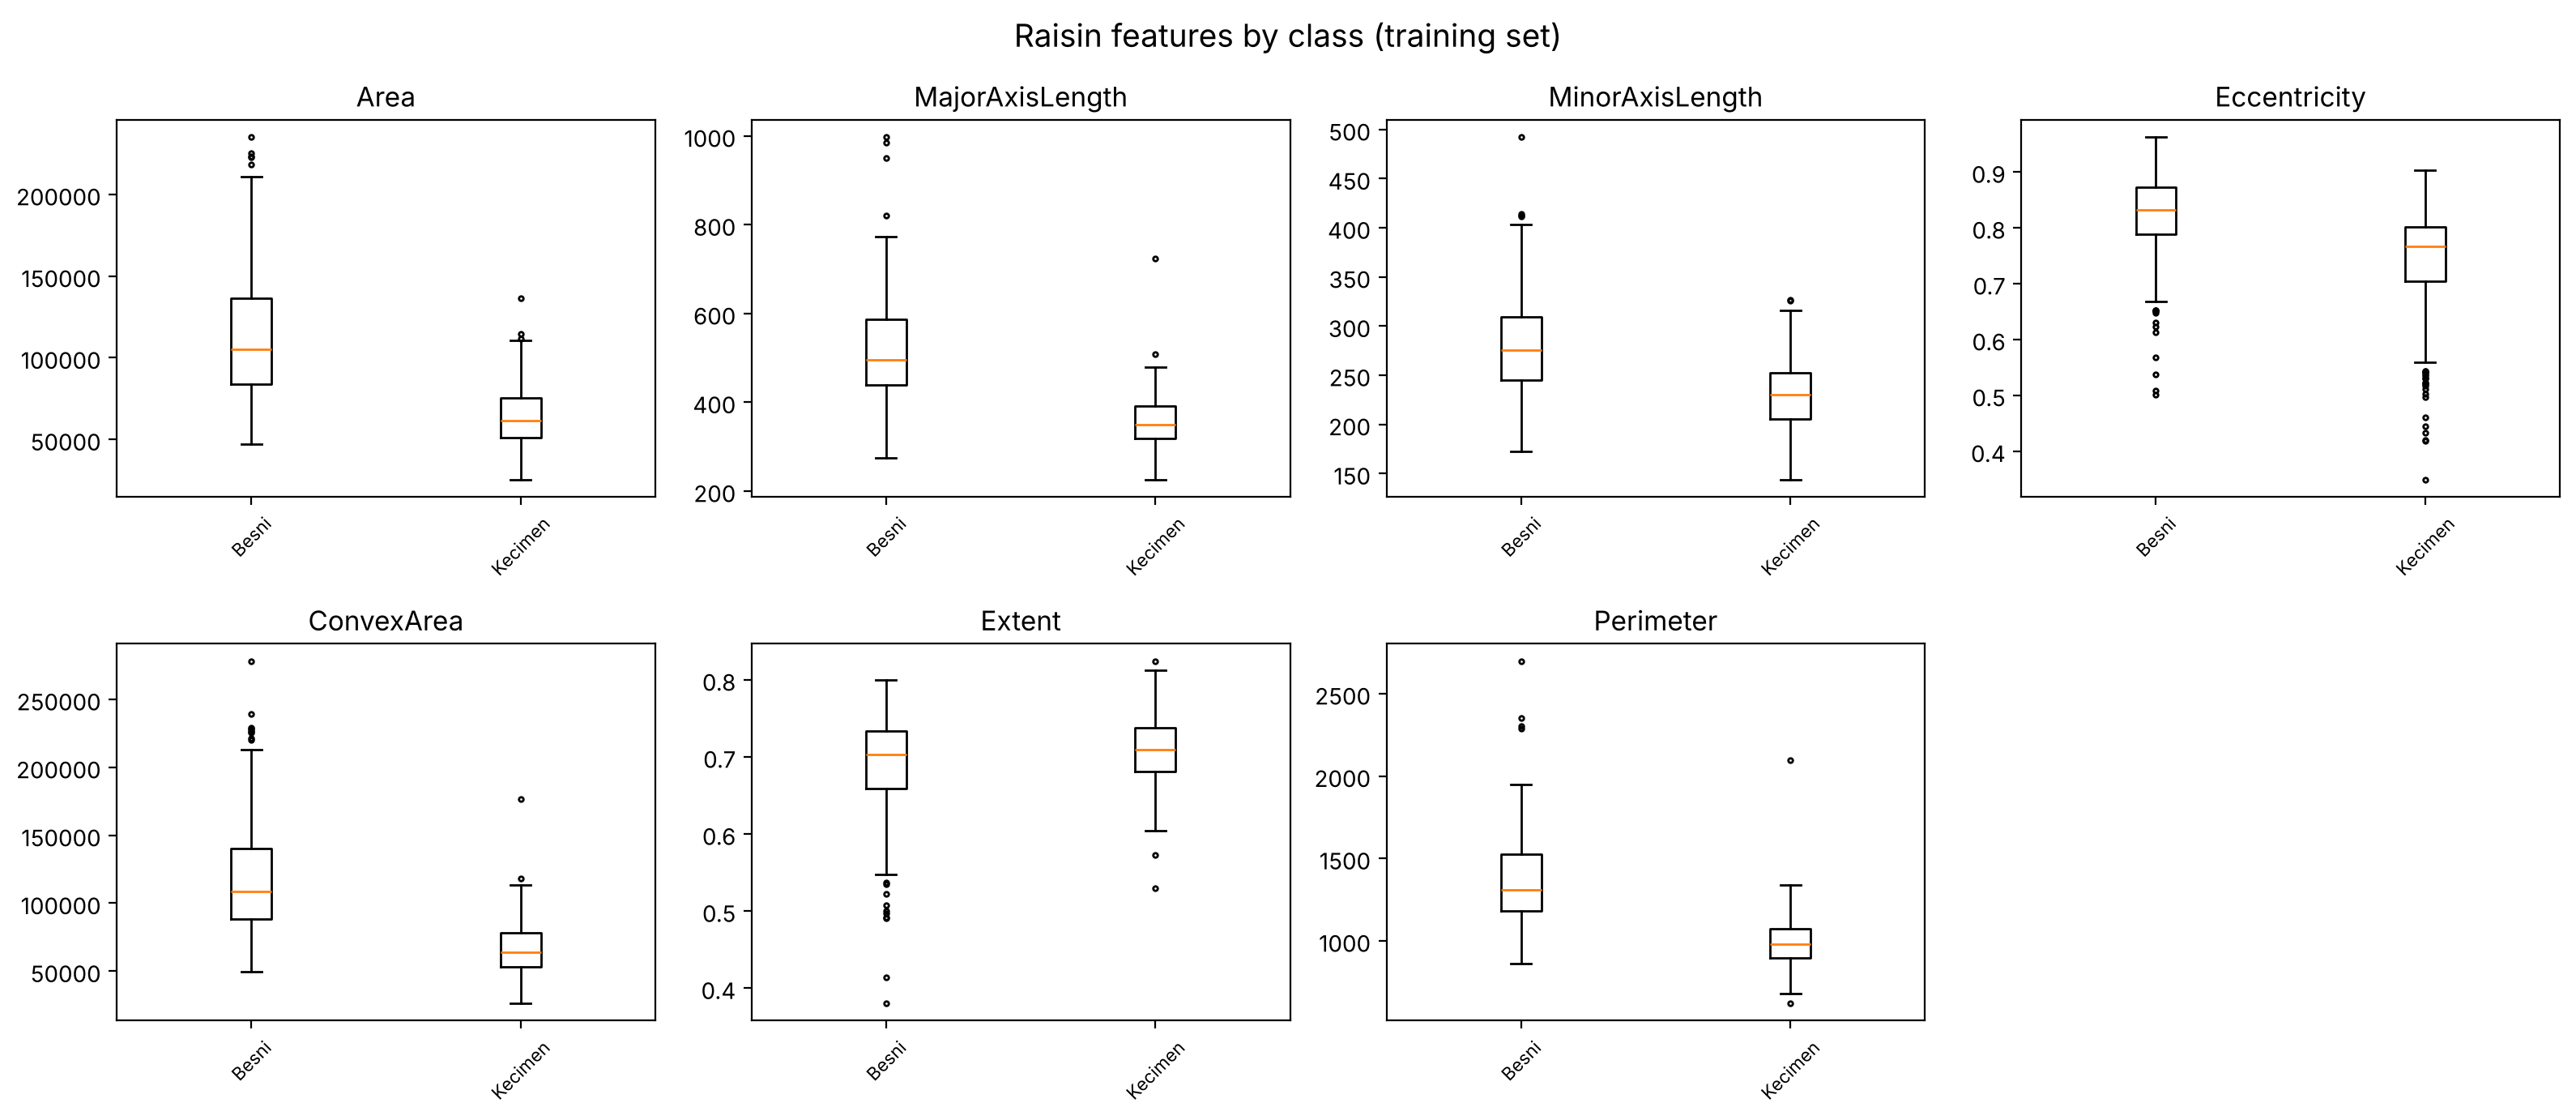

In [9]:
y_train_names = pd.Series(class_names[y_train], index=X_train.index)
plot_boxplots(X_train, y_train_names, "Raisin features by class (training set)",
              "fig12_raisin_boxplots.png")

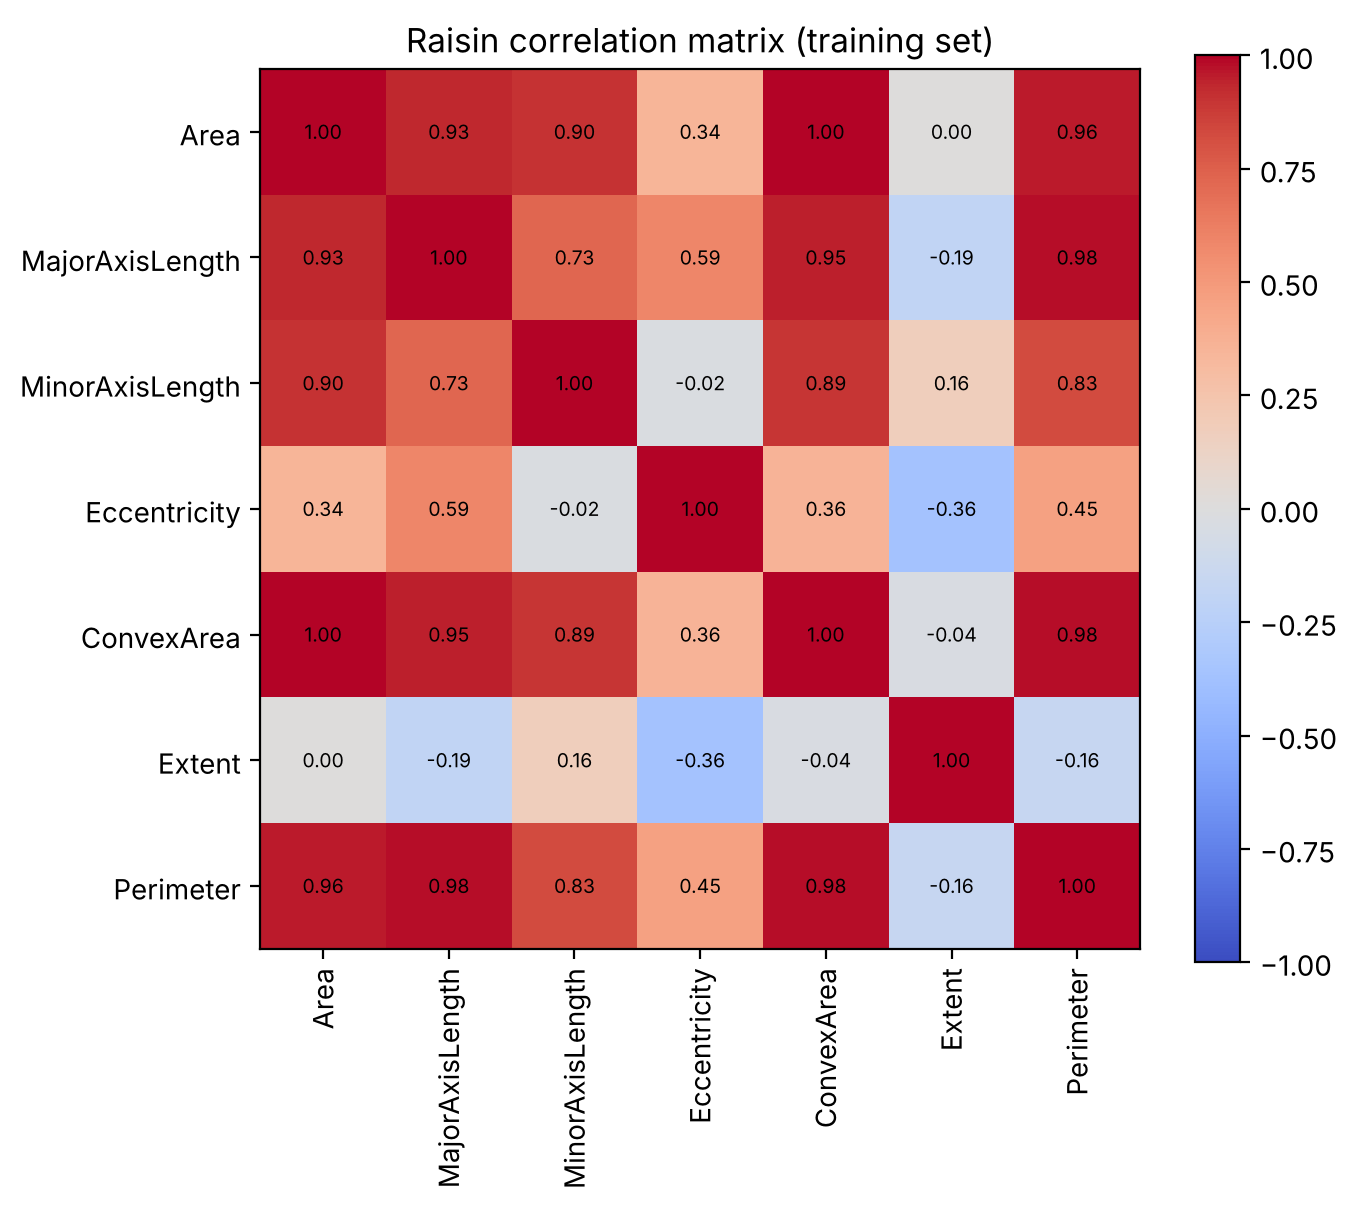

In [10]:
corr = plot_correlation(X_train, "Raisin correlation matrix (training set)",
                        "fig13_raisin_correlation.png")

In [11]:
pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.95:
            pairs.append((corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)))
pd.DataFrame(pairs, columns=["Feature 1", "Feature 2", "Correlation"])

,Feature 1,Feature 2,Correlation
0,Area,ConvexArea,0.996
1,Area,Perimeter,0.960
2,MajorAxisLength,Perimeter,0.978
3,ConvexArea,Perimeter,0.977


In [12]:
# outliers: number of points outside 1.5*IQR (training set)
count_outliers(X_train)

ConvexArea         35
Eccentricity       34
Area               33
Extent             20
MinorAxisLength    19
Perimeter          15
MajorAxisLength    14
dtype: int64

In [13]:
# look closer at the largest values of Perimeter and MajorAxisLength
X_train.assign(Class=y_train_names).sort_values("Perimeter", ascending=False).head(5)

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
487,210923,984.045491,367.279532,0.927737,278217,0.507352,2697.753,Besni
836,181126,949.662672,293.386698,0.951082,225592,0.414154,2352.029,Besni
506,182160,997.291941,271.872395,0.962124,221527,0.379856,2303.690,Besni
694,172783,820.724022,352.193680,0.903245,219952,0.496937,2289.889,Besni
290,136340,722.853917,311.341355,0.902490,176818,0.529774,2098.263,Kecimen


**Observations from the EDA and the decisions they lead to:**
1. **Different scales** (Area up to about 235,000, Extent between 0.38 and 0.82) -> StandardScaler inside the
   Pipeline for Logistic Regression and SVM, exactly as for Dry Bean.
2. **Balanced classes** (450 / 450) -> accuracy is meaningful here, and macro F1 = weighted F1.
3. **Strong multicollinearity**: Area-ConvexArea 0.996, MajorAxisLength-Perimeter 0.978, ConvexArea-Perimeter 0.977.
   We test removing ConvexArea and Perimeter in Stage 6.
4. **Outliers in Perimeter and MajorAxisLength**: the largest values (for example Perimeter 2,698) belong mostly to
   Besni grains, which are bigger on average (fig12). They are real large raisins, not errors, and the dataset
   is small (720 training rows), so we **keep them**. Random Forest is not sensitive to them, and the scaler only
   shifts and stretches the values.
5. **Besni grains are larger** in all size features, but the two boxes overlap a lot (fig12), so we expect an
   accuracy well below 100%.

## Stage 6: Feature selection (only if there is a reason)
ConvexArea is almost a copy of Area, and Perimeter is very close to MajorAxisLength and Area.
We test with CV on the training set whether removing them helps.

In [14]:
redundant = ["ConvexArea", "Perimeter"]
X_train_reduced = X_train.drop(columns=redundant)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

rows = []
for name, (pipe, grid) in get_models().items():
    all_f = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    red_f = cross_val_score(pipe, X_train_reduced, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    rows.append([name, round(all_f, 4), round(red_f, 4)])

pd.DataFrame(rows, columns=["Model (default settings)", "CV F1 macro - all 7 features",
                            "CV F1 macro - without " + ", ".join(redundant)])

,Model (default settings),CV F1 macro - all 7 features,"CV F1 macro - without ConvexArea, Perimeter"
0,Logistic Regression,0.8660,0.8600
1,Random Forest,0.8576,0.8489
2,SVM,0.8583,0.8602


**Decision:** removing ConvexArea and Perimeter makes the CV macro F1 slightly **worse** for Logistic Regression
and Random Forest and slightly better for SVM. Since there is no clear gain, we **keep all 7 features**.

## Stage 7: Training and tuning
Same models and same grids as Dry Bean (see `src/utils.py`), scored with `f1_macro`.
The only difference: **RepeatedStratifiedKFold (5 folds x 3 repeats)** because the dataset is small.

In [15]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

best_models = {}
tuning_info = {}

for name, (pipe, grid) in get_models().items():
    search, tuning_time = tune_model(pipe, grid, X_train, y_train, cv)
    best_models[name] = search.best_estimator_
    tuning_info[name] = {"best_params": search.best_params_,
                         "cv_f1": search.best_score_,
                         "cv_std": search.cv_results_["std_test_score"][search.best_index_],
                         "tuning_time": tuning_time,
                         "fit_time": search.refit_time_}
    print(f"{name}: best params = {clean_params(search.best_params_)}, "
          f"CV F1 macro = {search.best_score_:.4f} (+/- {tuning_info[name]['cv_std']:.4f}), "
          f"tuning time = {tuning_time:.1f} s")

Logistic Regression: best params = C=0.1, CV F1 macro = 0.8665 (+/- 0.0210), tuning time = 0.5 s


Random Forest: best params = max_depth=10, min_samples_split=5, n_estimators=200, CV F1 macro = 0.8614 (+/- 0.0240), tuning time = 55.5 s


SVM: best params = C=0.1, kernel=linear, CV F1 macro = 0.8679 (+/- 0.0182), tuning time = 1.7 s


## Stage 8: Final evaluation on the test set
Same metrics as Dry Bean. Because the classes are balanced, macro F1 and weighted F1 are the same here.
We also add **ROC-AUC** (optional in the plan), which measures how well the model ranks Kecimen above Besni.

In [16]:
results = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    row = {"Model": name}
    row.update(get_scores(y_test, y_pred))
    # SVM has no predict_proba here, so we use decision_function for its ROC-AUC
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)
    row["ROC-AUC"] = roc_auc_score(y_test, scores)
    row["Best Params"] = clean_params(tuning_info[name]["best_params"])
    row["Training Time (s)"] = round(tuning_info[name]["fit_time"], 3)
    row["Tuning Time (s)"] = round(tuning_info[name]["tuning_time"], 1)
    results.append(row)

results_df = pd.DataFrame(results)
results_df.to_csv(TABLE_DIR + "raisin_results.csv", index=False)
results_df.round(4)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC,Best Params,Training Time (s),Tuning Time (s)
0,Logistic Regression,0.8778,0.8825,0.8778,0.8774,0.8774,0.9136,C=0.1,0.005,0.5
1,Random Forest,0.8667,0.8758,0.8667,0.8659,0.8659,0.9238,"max_depth=10, min_samples_split=5, n_estimator...",0.269,55.5
2,SVM,0.8722,0.8779,0.8722,0.8717,0.8717,0.9147,"C=0.1, kernel=linear",0.007,1.7


### Overfitting check

In [17]:
gap_rows = []
for name, model in best_models.items():
    train_f1 = f1_score(y_train, model.predict(X_train), average="macro")
    test_f1 = f1_score(y_test, model.predict(X_test), average="macro")
    gap_rows.append([name, train_f1, tuning_info[name]["cv_f1"], tuning_info[name]["cv_std"],
                     test_f1, train_f1 - test_f1])

gap_df = pd.DataFrame(gap_rows, columns=["Model", "Train F1 (macro)", "CV F1 (macro)", "CV std",
                                         "Test F1 (macro)", "Train - Test gap"])
gap_df.to_csv(TABLE_DIR + "raisin_overfitting.csv", index=False)
gap_df.round(4)

,Model,Train F1 (macro),CV F1 (macro),CV std,Test F1 (macro),Train - Test gap
0,Logistic Regression,0.8652,0.8665,0.0210,0.8774,-0.0122
1,Random Forest,0.9653,0.8614,0.0240,0.8659,0.0994
2,SVM,0.8680,0.8679,0.0182,0.8717,-0.0038


**Observations (Table above):**
- On the test set **Logistic Regression is the best** (accuracy 0.878, macro F1 0.877), then SVM (0.872) and
  Random Forest (0.866). In CV the order was SVM, LR, RF.
- **All differences are smaller than one CV standard deviation** (about 0.02). With only 180 test rows, one more
  correct grain changes the accuracy by 0.56%. So the honest conclusion is: the three models perform about the
  same on Raisin, with the linear models slightly ahead.
- Both LR and SVM picked **simple settings** (C=0.1, and a linear kernel for SVM): strong regularization and a
  straight-line boundary. This fits a small dataset where the two classes are separated mainly by size.
- Random Forest has the **best ROC-AUC (0.924)**, so it ranks the grains well, but with the default 0.5 threshold its
  F1 is the lowest.
- **Overfitting:** Random Forest has a large gap (train F1 0.965 vs test 0.866, about 0.10). LR and SVM have almost
  no gap (their test score is even slightly higher than their train score, which happens by chance on a small test set).

### Confusion matrices (fig14 to fig16) and ROC curves (fig17)

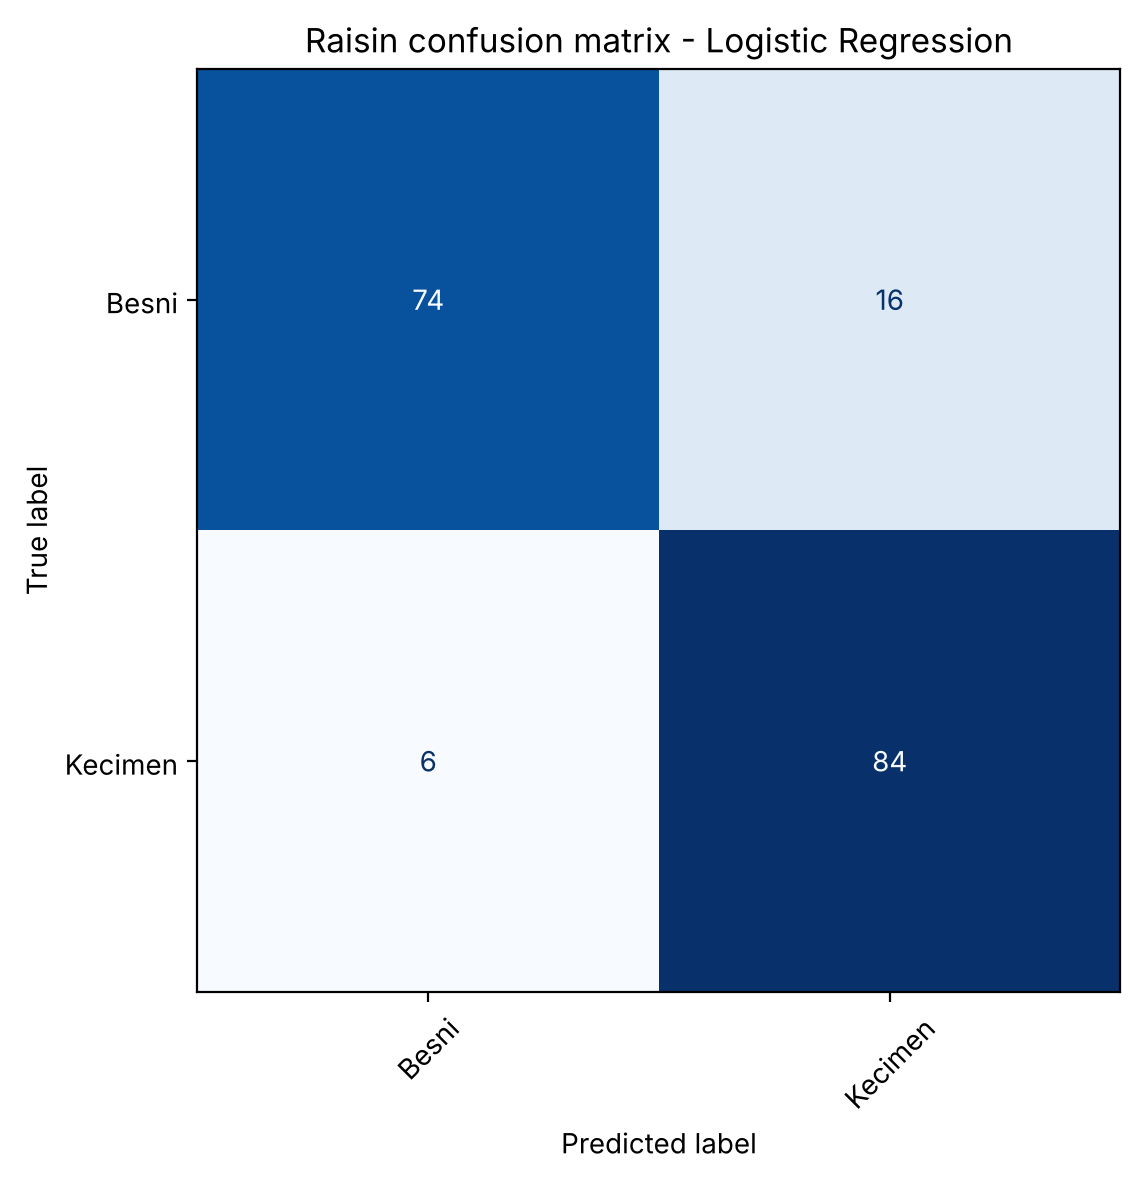

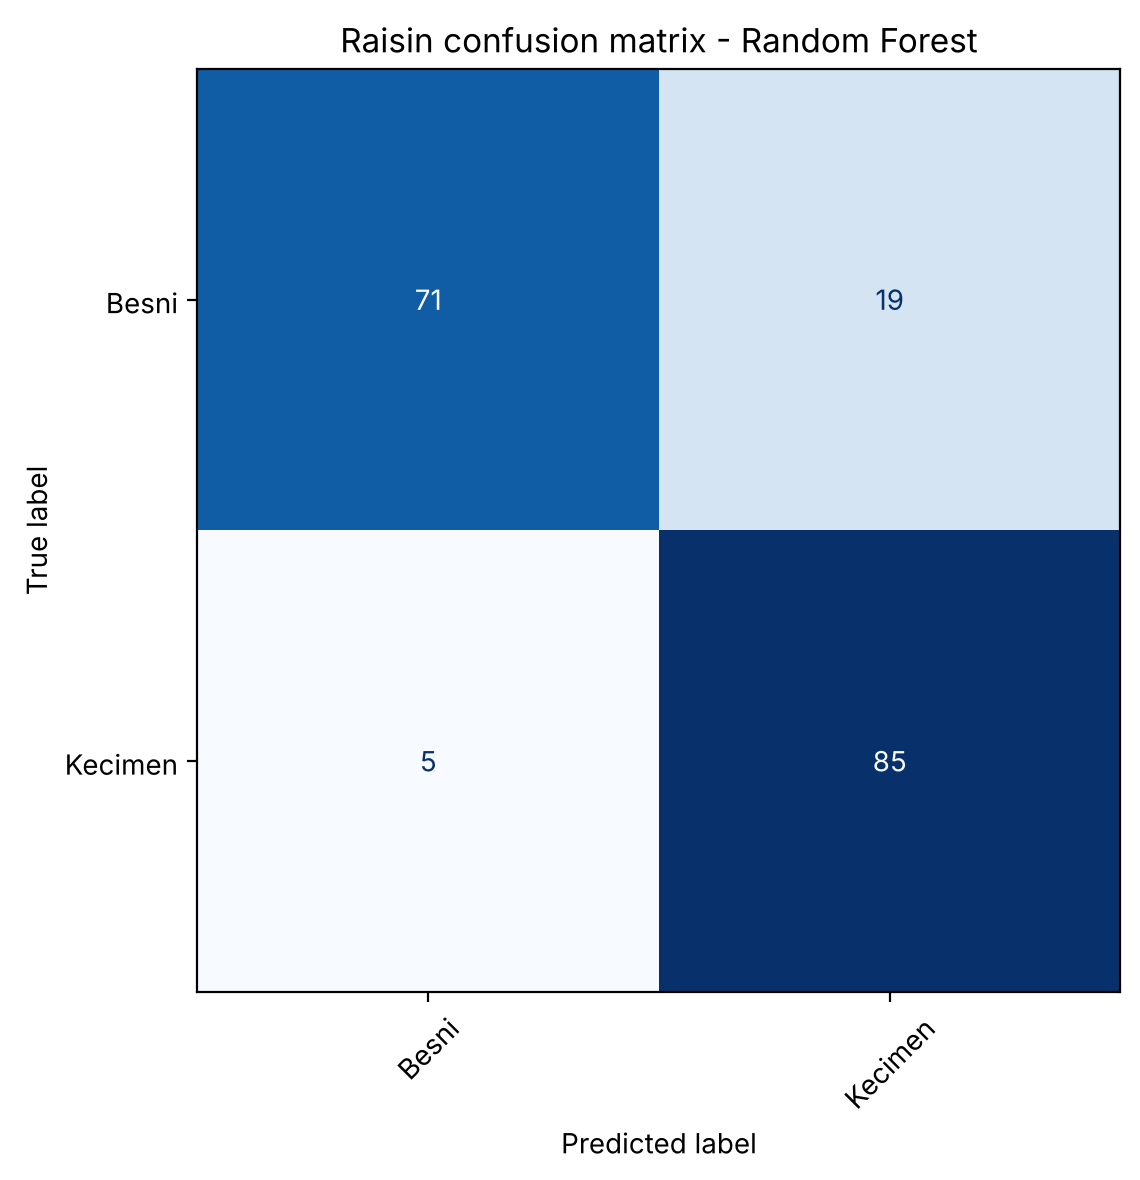

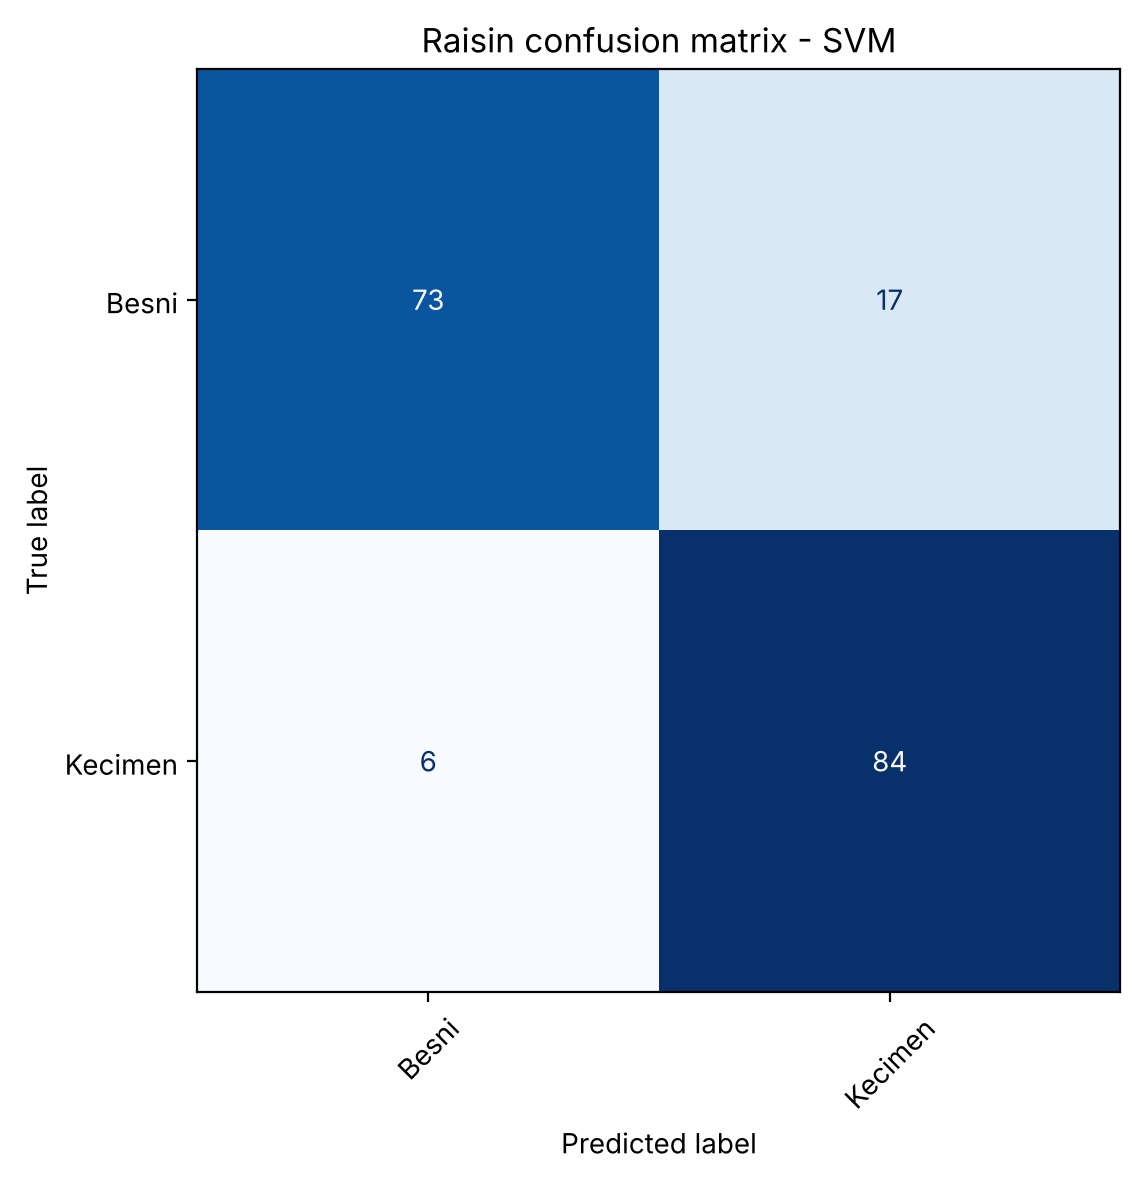

In [18]:
fig_num = 14
for name, model in best_models.items():
    short = name.lower().replace(" ", "_")
    plot_confusion(model, X_test, y_test, class_names,
                   f"Raisin confusion matrix - {name}",
                   f"fig{fig_num:02d}_raisin_cm_{short}.png")
    fig_num += 1

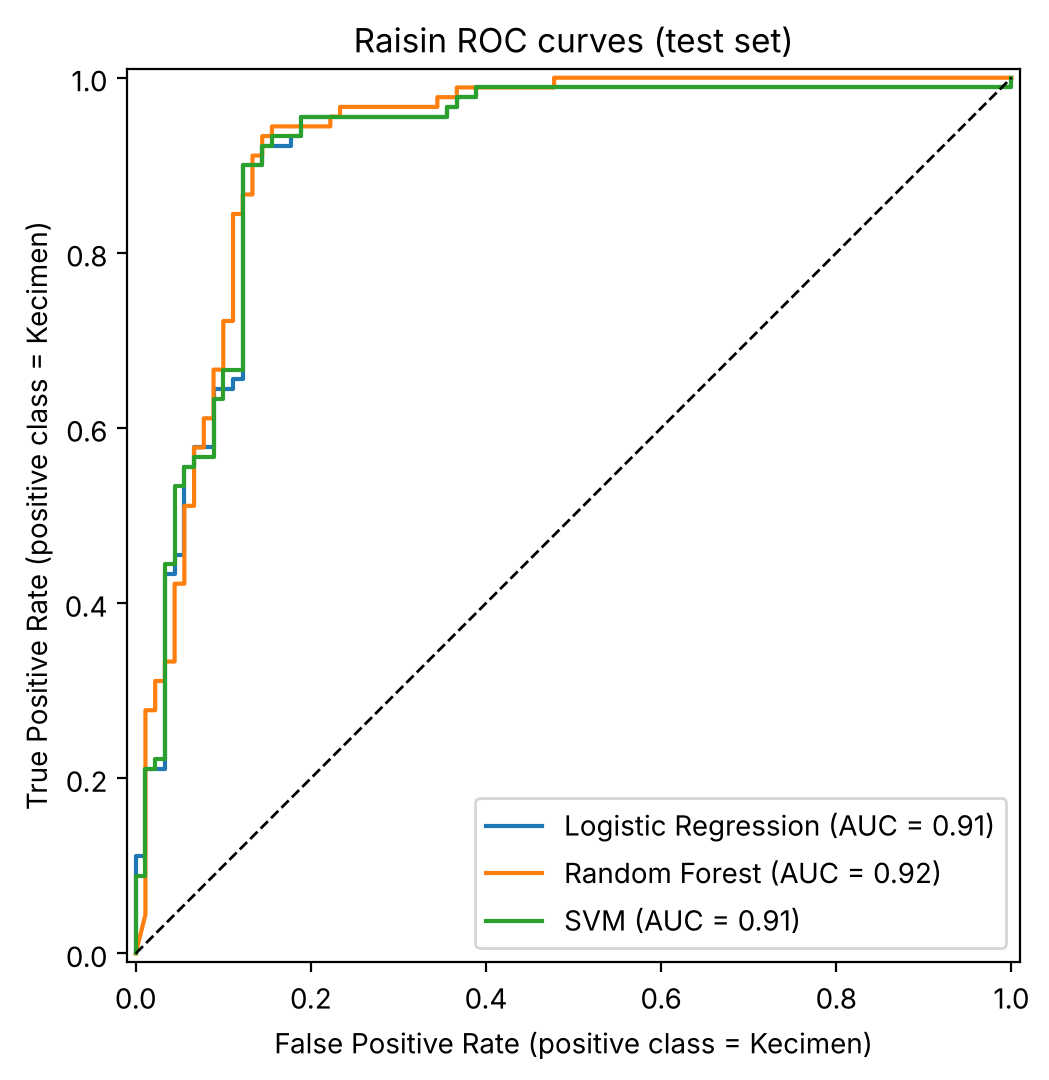

In [19]:
# fig17: ROC curves of the three models on the test set (positive class = Kecimen)
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_title("Raisin ROC curves (test set)")
ax.set_xlabel("False Positive Rate (positive class = Kecimen)")
ax.set_ylabel("True Positive Rate (positive class = Kecimen)")
plt.tight_layout()
plt.savefig(FIG_DIR + "fig17_raisin_roc.png", dpi=150)
plt.show()

In [20]:
from sklearn.metrics import classification_report

best_name = results_df.sort_values("F1 (macro)", ascending=False).iloc[0]["Model"]
print("Best model on Raisin:", best_name, "\n")
print(classification_report(y_test, best_models[best_name].predict(X_test),
                            target_names=class_names, digits=3))

Best model on Raisin: Logistic Regression 

              precision    recall  f1-score   support

       Besni      0.925     0.822     0.871        90
     Kecimen      0.840     0.933     0.884        90

    accuracy                          0.878       180
   macro avg      0.883     0.878     0.877       180
weighted avg      0.882     0.878     0.877       180



**Errors:** the best model (LR) finds Kecimen better (recall 0.933) than Besni (recall 0.822): most errors are
Besni grains predicted as Kecimen. In fig12 the small Besni grains overlap with the Kecimen range, so a
size-based boundary misclassifies them.

## Stage 9: Feature importance

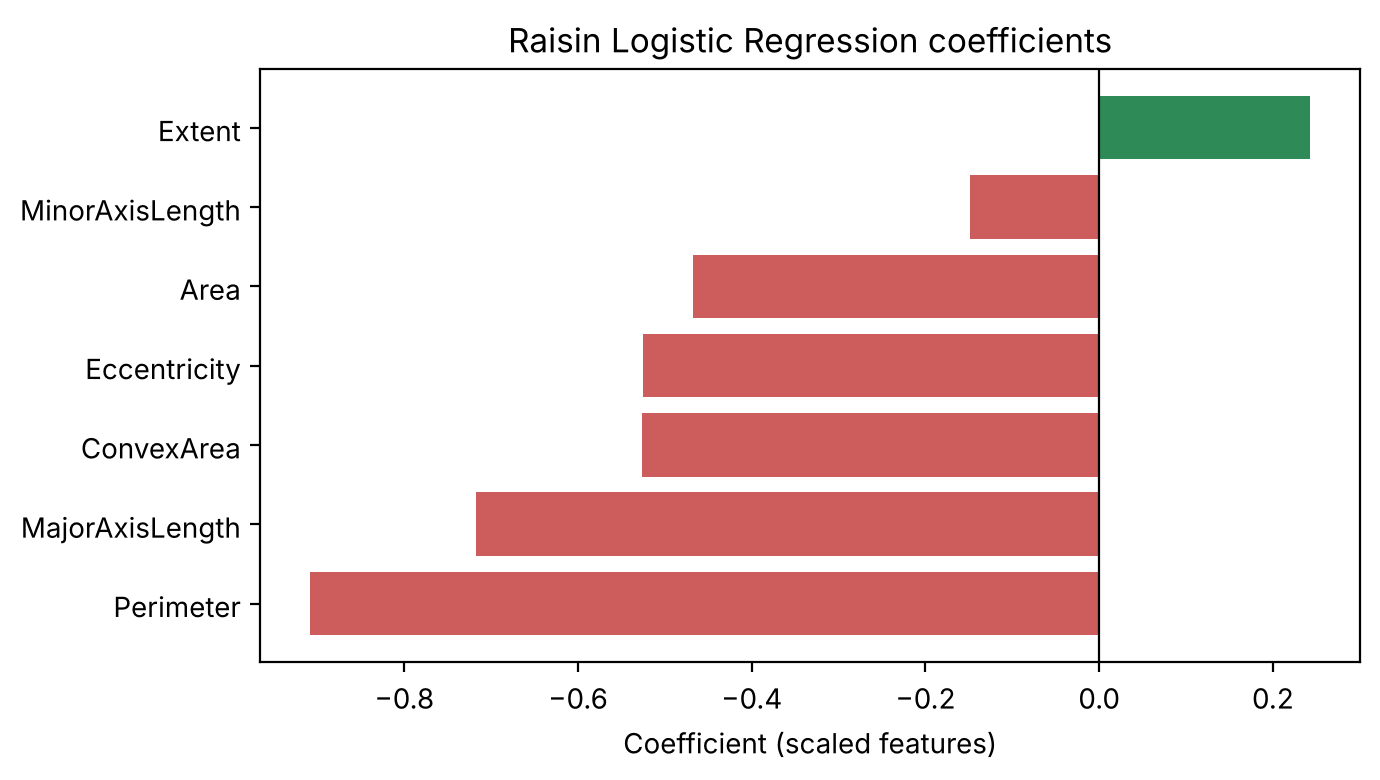

Perimeter         -0.908
MajorAxisLength   -0.718
ConvexArea        -0.527
Eccentricity      -0.525
Area              -0.468
MinorAxisLength   -0.149
Extent             0.243
dtype: float64

In [21]:
# fig18: Logistic Regression coefficients (binary problem -> one coefficient per feature)
# positive coefficient = pushes the prediction towards Kecimen (class 1)
lr = best_models["Logistic Regression"].named_steps["model"]
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
colors = ["indianred" if c < 0 else "seagreen" for c in coef]
plt.barh(coef.index, coef.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (scaled features)")
plt.title("Raisin Logistic Regression coefficients")
plt.tight_layout()
plt.savefig(FIG_DIR + "fig18_raisin_lr_coefficients.png", dpi=150)
plt.show()
coef.round(3)

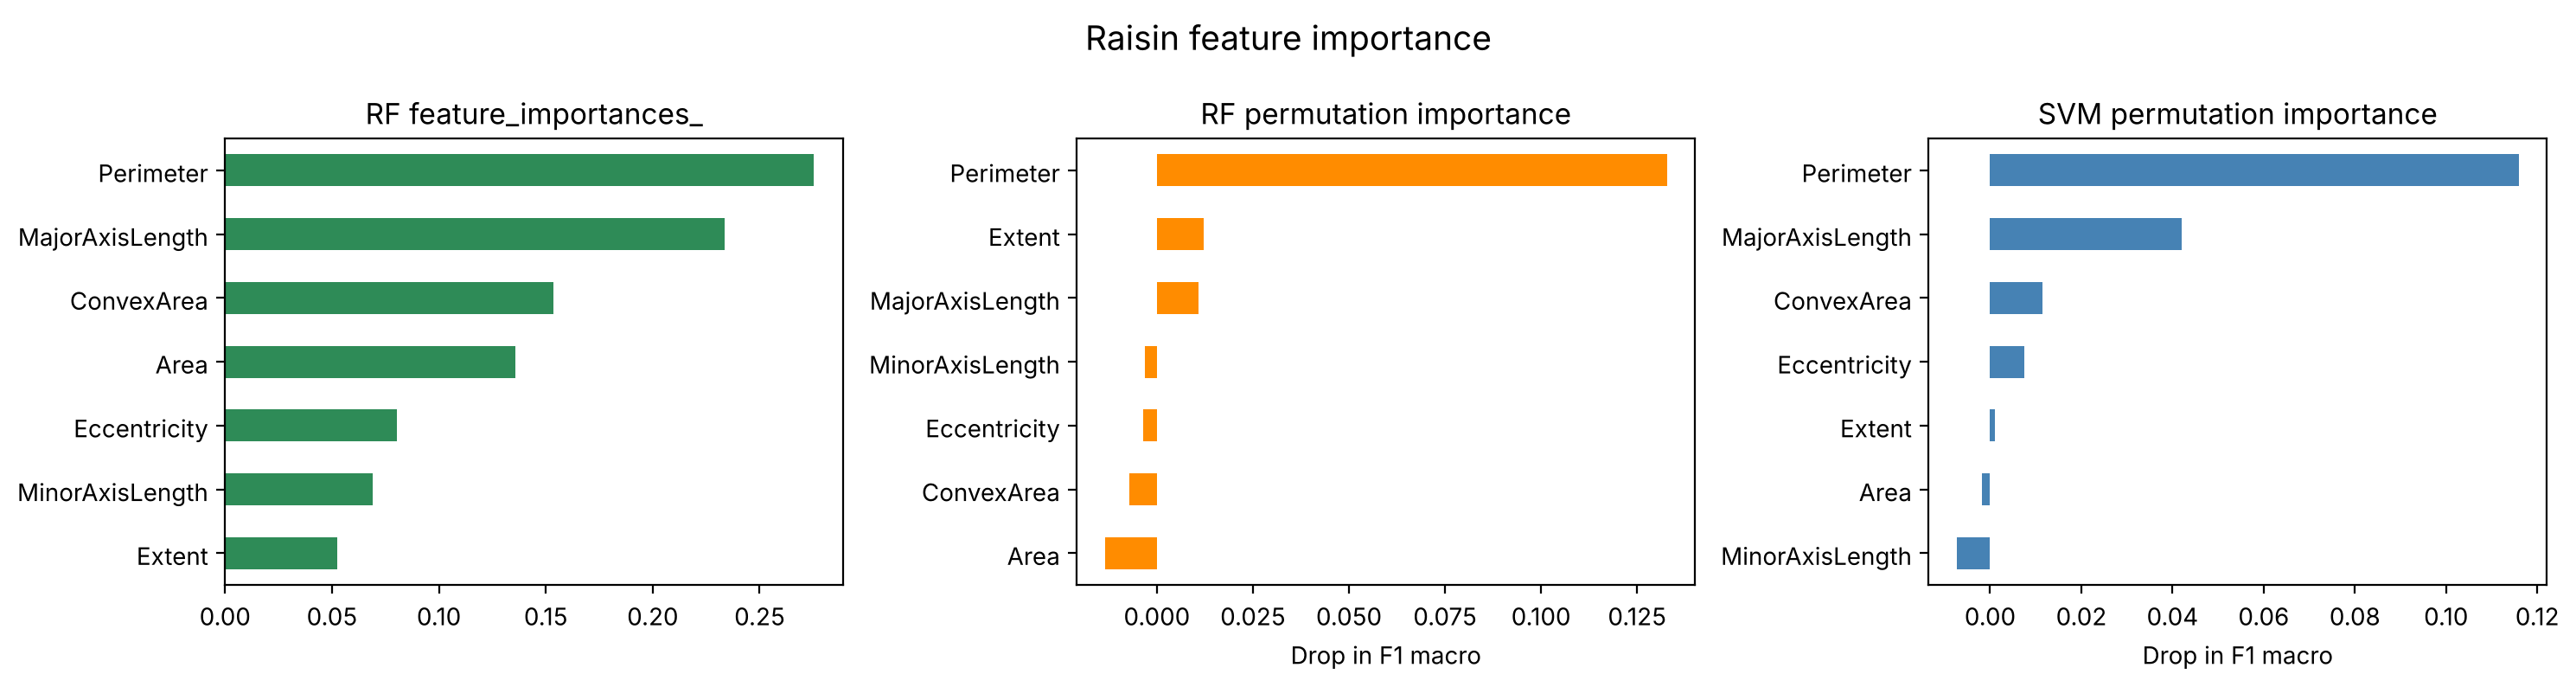

In [22]:
rf = best_models["Random Forest"].named_steps["model"]
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
rf_perm = get_permutation_importance(best_models["Random Forest"], X_test, y_test)
svm_perm = get_permutation_importance(best_models["SVM"], X_test, y_test)

# fig19
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rf_imp.plot.barh(ax=axes[0], color="seagreen", title="RF feature_importances_")
rf_perm.plot.barh(ax=axes[1], color="darkorange", title="RF permutation importance")
svm_perm.plot.barh(ax=axes[2], color="steelblue", title="SVM permutation importance")
for ax in axes[1:]:
    ax.set_xlabel("Drop in F1 macro")
fig.suptitle("Raisin feature importance", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR + "fig19_raisin_feature_importance.png", dpi=150)
plt.show()

**Discussion of feature importance:**
- **Perimeter is the most important feature** for all three methods (RF impurity, RF permutation and SVM permutation),
  and it also has the largest Logistic Regression coefficient (-0.91: a larger perimeter pushes the prediction
  towards Besni). MajorAxisLength is second for most methods. This makes sense: Besni grains are longer and larger.
- **Area and ConvexArea get almost zero (or slightly negative) permutation importance** even though they clearly
  differ between classes. The reason is the correlation: when Area is shuffled, the model can still use
  ConvexArea and Perimeter, which carry the same information. A negative value means shuffling the feature by chance
  did not hurt the score on this small test set.
- In Logistic Regression all size features have negative coefficients of similar size, which spreads the effect of
  "size" over several correlated features. We should not read each coefficient alone.

In [23]:
import json
params = {name: info["best_params"] for name, info in tuning_info.items()}
with open(TABLE_DIR + "raisin_best_params.json", "w") as f:
    json.dump(params, f, indent=2, default=str)
print(params)

{'Logistic Regression': {'model__C': 0.1}, 'Random Forest': {'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}, 'SVM': {'model__C': 0.1, 'model__kernel': 'linear'}}
